---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 04: Task 4, Frequent Pattern Mining dengan FP-Growth.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Implementasi FP-Growth**](#3)
4. [**Eksperimen Empat Min Support (Task 4.1)**](#4)
5. [**Validasi dengan mlxtend**](#5)
6. [**Analisis Frequent Itemsets (Task 4.2 sampai 4.5)**](#6)
7. [**Interpretasi (Task 4.6)**](#7)
8. [**Ringkasan dan Langkah Berikutnya**](#8)

---

# Introduction <a name="1"></a>

---

## Overview

*Task 4 mencari kombinasi konferensi yang sering muncul bersama dalam riwayat publikasi author. Notebook ini mengerjakan sisi FP-Growth pada author-based transactional database dari notebook `02_transactions`. Sisi Apriori dikerjakan pada notebook `03_apriori`, dan perbandingan keduanya pada notebook `06_performance`.*

## Aim

*Task 4.1: menemukan frequent itemsets pada min support 0,1%, 0,5%, 1%, dan 2%.*

*Task 4.2 dan 4.3: memisahkan 1-, 2-, dan 3-itemsets, lalu menampilkan 10 itemsets dengan support tertinggi.*

*Task 4.4 dan 4.5: menganalisis pengaruh min support terhadap jumlah itemsets dan mengidentifikasi kombinasi konferensi yang paling sering muncul bersama.*

*Task 4.6: menginterpretasikan pola yang ditemukan.*

## Metric

***Support** itemset $X$ adalah proporsi transaksi yang memuat seluruh item pada $X$. Penyebutnya selalu seluruh transaksi author-based, yaitu 1.821.757, termasuk transaksi yang dilewati saat membangun FP-tree.*

$$\text{support}(X) = \frac{|\{t \in D : X \subseteq t\}|}{|D|}$$

*Itemset frequent jika support-nya minimal min support. Dalam hitungan transaksi, ambangnya adalah bilangan bulat terkecil $c$ dengan $c / |D| \ge \text{min\_sup}$.*

## Approach

*FP-Growth memadatkan database menjadi FP-tree dalam dua pemindaian, lalu menambang pola secara rekursif dari conditional pattern base tanpa membangkitkan kandidat. Implementasi mengikuti aturan bab metodologi: item yang tidak frequent dipangkas lebih dulu, transaksi dengan kurang dari dua item frequent tidak dimasukkan ke pohon (support 1-itemset tetap dari pemindaian pertama), dan waktu pembentukan pohon dilaporkan terpisah dari waktu penambangan.*

*Kode algoritma berada di `src/fpgrowth.py` agar dapat dipakai ulang oleh notebook 05, 06, dan 07, dan sudah diuji dengan `pytest` (contoh buku teks, brute force, dan `mlxtend`). Isi modul ditampilkan pada bagian 3.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Prasyaratnya adalah notebook `02_transactions` sudah dijalankan sehingga `data/processed/tx_author.parquet` dan `tx_items.csv` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas scipy matplotlib pyarrow mlxtend

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import inspect
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

## Seed Everything

FP-Growth bersifat deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang min support, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"
    FPM_DIR = ROOT / "outputs" / "fpgrowth"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR = PROC_DIR / "tx_author.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
    TOP_K = 10

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR, CFG.FPM_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
import fpgrowth as fpgrowth_module
from fpgrowth import fpgrowth, render_tree, to_frame
from fpm_data import load_horizontal, load_item_names
from validation import compare_itemsets, mlxtend_reference

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)


def id_ticks(ax, axis="x"):
    formatter = FuncFormatter(lambda v, _: fmt_id(v, 0 if float(v).is_integer() else 1))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def tag(ms):
    return f"{ms * 100:g}".replace(".", "p")

## Load Dataset

Tabel panjang author-based diubah ke bentuk horizontal, yaitu list frozenset kode item per transaksi. Bentuk ini sama dengan masukan Apriori pada notebook 03. Waktu pemuatan tidak termasuk pengukuran.

In [6]:
transactions = load_horizontal(CFG.TX_AUTHOR)
names = load_item_names(CFG.ITEMS)
N = len(transactions)
print(f"Transaksi: {fmt_id(N)} | item unik: {fmt_id(len(names))}")

Transaksi: 1.821.757 | item unik: 4.373


---

# Implementasi FP-Growth <a name="3"></a>

---

## 3.1 Kode

Seluruh isi `src/fpgrowth.py` ditampilkan di bawah. Setiap node FP-tree menyimpan `item`, `count`, `parent`, dan `children`, dan header table memetakan item ke daftar node-nya.

In [7]:
print(inspect.getsource(fpgrowth_module))

"""FP-Growth (Han, Pei, dan Yin, 2000) untuk transactional database berbentuk horizontal."""
from __future__ import annotations

import math
import time
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import Dict, FrozenSet, Iterable, Iterator, List, Mapping, Optional, Sequence, Tuple

import pandas as pd


def min_count_for(min_support: float, n_transactions: int) -> int:
    """Count terkecil c sehingga c / n_transactions >= min_support (minimal 1)."""
    c = math.ceil(min_support * n_transactions)
    while c > 0 and (c - 1) / n_transactions >= min_support:
        c -= 1
    while c / n_transactions < min_support:
        c += 1
    return max(c, 1)


def order_items(items: Iterable[int], counts: Mapping[int, int]) -> Tuple[int, ...]:
    """Urutan item di FP-tree: count menurun, lalu id item menaik."""
    return tuple(sorted(items, key=lambda i: (-counts[i], i)))


class FPNode:
    __slots__ = ("item", "count", "parent", "childr

## 3.2 Contoh Kecil

Sebelum dijalankan pada data DBLP, FP-Growth diperiksa pada contoh buku teks Han, Kamber, dan Pei (2012), sembilan transaksi dengan item I1 sampai I5 dan min support 2/9. Hasil yang benar adalah 13 frequent itemsets.

In [8]:
toy = [frozenset(t) for t in ([1, 2, 5], [2, 4], [2, 3], [1, 2, 4], [1, 3], [2, 3], [1, 3], [1, 2, 3, 5], [1, 2, 3])]
toy_names = {i: f"I{i}" for i in range(1, 6)}
toy_result = fpgrowth(toy, 2 / 9)
print(render_tree(toy_result.tree, toy_names))
to_frame(toy_result, toy_names)[["names", "length", "count", "support"]]

I2:7
  I1:4
    I3:2
      I5:1
    I4:1
    I5:1
  I3:2
  I4:1
I1:2
  I3:2


,names,length,count,support
0,I2,1,7,0.777778
1,I1,1,6,0.666667
2,I3,1,6,0.666667
3,I1 + I2,2,4,0.444444
4,I1 + I3,2,4,0.444444
5,I2 + I3,2,4,0.444444
6,I4,1,2,0.222222
7,I5,1,2,0.222222
8,I1 + I5,2,2,0.222222
9,I2 + I4,2,2,0.222222


---

# Eksperimen Empat Min Support (Task 4.1) <a name="4"></a>

---

FP-Growth dijalankan sekali untuk setiap min support. Waktu pembentukan pohon (`t_build`) dan waktu penambangan (`t_mine`) dicatat terpisah. Pengukuran berulang untuk perbandingan performa dilakukan pada notebook 06. FP-tree tidak disimpan setelah penambangan (`keep_tree=False`) agar memori cukup untuk validasi.

In [9]:
results = {}
for ms in CFG.MIN_SUPPORTS:
    res = fpgrowth(transactions, ms, keep_tree=False)
    results[ms] = res
    print(f"min_sup {pct_id(ms * 100)} | min_count {fmt_id(res.min_count)} | itemsets {fmt_id(len(res.itemsets))} "
          f"| build {res.t_build:.2f} s | mine {res.t_mine:.2f} s")

frames = {ms: to_frame(res, names) for ms, res in results.items()}
for ms, df in frames.items():
    df.assign(itemset=df["itemset"].apply(list)).to_parquet(CFG.FPM_DIR / f"itemsets_{tag(ms)}.parquet", index=False)

min_sup 0,1% | min_count 1.822 | itemsets 1.514 | build 6.42 s | mine 5.29 s


min_sup 0,5% | min_count 9.109 | itemsets 88 | build 3.02 s | mine 0.68 s


min_sup 1,0% | min_count 18.218 | itemsets 30 | build 2.36 s | mine 0.18 s


min_sup 2,0% | min_count 36.436 | itemsets 6 | build 2.15 s | mine 0.00 s


---

# Validasi dengan mlxtend <a name="5"></a>

---

Setiap hasil dibandingkan dengan `mlxtend.frequent_patterns.fpgrowth` pada database yang sama. Itemset dan count harus identik.

In [10]:
checks = pd.DataFrame([
    {"min_support": ms, **compare_itemsets(res.itemsets, mlxtend_reference(transactions, ms))}
    for ms, res in results.items()
])
save_table(checks, "t4_fpgrowth_validasi_mlxtend.csv", index=False)
assert checks["identical"].all(), "hasil FP-Growth berbeda dengan mlxtend"
checks

,min_support,n_ours,n_ref,missing,extra,count_mismatch,identical
0,0.001,1514,1514,0,0,0,True
1,0.005,88,88,0,0,0,True
2,0.010,30,30,0,0,0,True
3,0.020,6,6,0,0,0,True


---

# Analisis Frequent Itemsets (Task 4.2 sampai 4.5) <a name="6"></a>

---

## 6.1 Jumlah Itemset per Ukuran (Task 4.2)

Itemset dikelompokkan menurut ukurannya. Kolom `k4+` menampung itemset berisi empat item atau lebih.

In [11]:
def length_counts(df):
    return df["length"].clip(upper=4).value_counts().reindex([1, 2, 3, 4], fill_value=0)

summary = pd.DataFrame([
    {"min_support": ms, "min_count": res.min_count, "itemsets": len(res.itemsets),
     **dict(zip(["k1", "k2", "k3", "k4+"], length_counts(frames[ms]).tolist())),
     "max_length": int(frames[ms]["length"].max()),
     "t_build_s": round(res.t_build, 3), "t_mine_s": round(res.t_mine, 3)}
    for ms, res in results.items()
])
save_table(summary, "t4_fpgrowth_ringkasan.csv", index=False)
summary

,min_support,min_count,itemsets,k1,k2,k3,k4+,max_length,t_build_s,t_mine_s
0,0.001,1822,1514,574,393,348,199,6,6.424,5.286
1,0.005,9109,88,66,21,1,0,3,3.017,0.680
2,0.010,18218,30,29,1,0,0,2,2.361,0.176
3,0.020,36436,6,6,0,0,0,1,2.152,0.000


> Pada min support 0,1% ditemukan 1.514 frequent itemsets: 574 1-itemset, 393 pasangan, 348 triple, dan 199 itemset berukuran empat sampai enam. Pada 0,5% tersisa 88 itemset dengan hanya satu triple, pada 1% tersisa 30 itemset dengan hanya satu pasangan, dan pada 2% hanya enam konferensi tunggal tanpa satu pun pasangan. Jadi 3-itemset hanya ada pada 0,1% dan 0,5%, dan tidak ada sama sekali pada 1% dan 2%.

## 6.2 Sepuluh Itemset dengan Support Tertinggi (Task 4.3)

Sepuluh teratas secara keseluruhan hampir pasti berisi 1-itemset, karena support sebuah itemset tidak pernah melebihi support item penyusunnya. Karena itu ditampilkan juga sepuluh teratas untuk itemset berukuran dua atau lebih.

In [12]:
cols = ["names", "length", "count", "support"]
for ms, df in frames.items():
    top = df.head(CFG.TOP_K)[cols]
    top_k2 = df[df["length"] >= 2].head(CFG.TOP_K)[cols]
    save_table(top, f"t4_fpgrowth_top10_{tag(ms)}.csv", index=False)
    save_table(top_k2, f"t4_fpgrowth_top10_k2plus_{tag(ms)}.csv", index=False)
    print(f"\nmin_sup {pct_id(ms * 100)}: semua ukuran")
    display(top.style.format({"support": "{:.4%}"}))
    print(f"min_sup {pct_id(ms * 100)}: ukuran >= 2 ({len(df[df['length'] >= 2])} itemset)")
    display(top_k2.style.format({"support": "{:.4%}"}))


min_sup 0,1%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%
6,IGARSS,1,35229,1.9338%
7,EMNLP,1,33954,1.8638%
8,ICML,1,31896,1.7508%
9,IROS,1,31249,1.7153%


min_sup 0,1%: ukuran >= 2 (940 itemset)


,names,length,count,support
29,ICML + NeurIPS,2,18503,1.0157%
31,ICLR + NeurIPS,2,17852,0.9799%
34,AAAI + NeurIPS,2,15973,0.8768%
36,CVPR + NeurIPS,2,15640,0.8585%
38,CVPR + ICCV,2,15441,0.8476%
48,ACL + EMNLP,2,14557,0.7991%
54,CVPR + ECCV,2,13752,0.7549%
56,ICLR + ICML,2,12947,0.7107%
60,AAAI + CVPR,2,12169,0.6680%
62,ICRA + IROS,2,11860,0.6510%



min_sup 0,5%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%
6,IGARSS,1,35229,1.9338%
7,EMNLP,1,33954,1.8638%
8,ICML,1,31896,1.7508%
9,IROS,1,31249,1.7153%


... (6 outputs left out)


min_sup 2,0%: semua ukuran


,names,length,count,support
0,NeurIPS,1,57800,3.1728%
1,CVPR,1,47664,2.6164%
2,AAAI,1,46437,2.5490%
3,ICASSP,1,42057,2.3086%
4,EMBC,1,39318,2.1582%
5,HCI,1,37884,2.0795%


min_sup 2,0%: ukuran >= 2 (0 itemset)


,names,length,count,support


> Sepuluh itemset teratas pada setiap min support selalu berupa konferensi tunggal, dipimpin NeurIPS (57.800 author, support 3,17%), CVPR (47.664), dan AAAI (46.437). Tidak ada kombinasi yang masuk sepuluh besar karena pasangan teratas, ICML + NeurIPS, hanya memiliki 18.503 author (support 1,02%), lebih kecil dari konferensi ke-10, IROS (31.249 author). Support pasangan itu sekitar sepertiga support NeurIPS sendiri.

## 6.3 Pengaruh Min Support (Task 4.4)

Sumbu y memakai skala symlog agar jumlah nol tetap terlihat dan rentang ratusan sampai ribuan dapat dibandingkan.

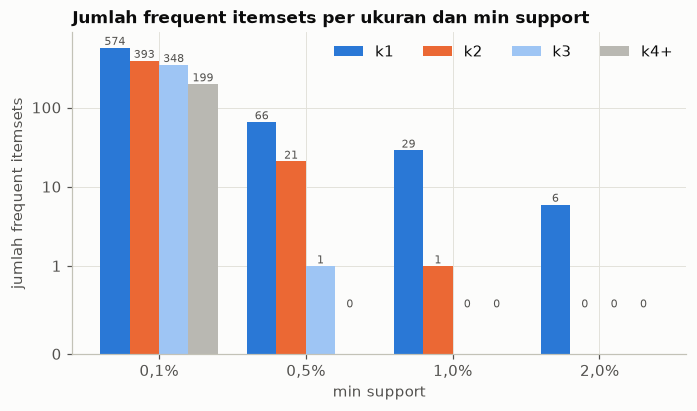

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(CFG.MIN_SUPPORTS))
width = 0.2
for j, (col, color) in enumerate(zip(["k1", "k2", "k3", "k4+"], [CFG.BLUE, CFG.ORANGE, CFG.BLUE_LIGHT, CFG.GRAY])):
    vals = summary[col].to_numpy()
    bars = ax.bar(x + (j - 1.5) * width, vals, width, color=color, label=col)
    for b, v in zip(bars, vals):
        ax.annotate(fmt_id(v), (b.get_x() + b.get_width() / 2, max(v, 0.5)), ha="center", va="bottom", fontsize=7.5, color=CFG.INK_2)
ax.set_yscale("symlog", linthresh=1)
id_ticks(ax, "y")
ax.set_xticks(x, [pct_id(ms * 100) for ms in CFG.MIN_SUPPORTS])
ax.set_xlabel("min support")
ax.set_ylabel("jumlah frequent itemsets")
ax.set_title("Jumlah frequent itemsets per ukuran dan min support")
ax.legend(ncol=4, loc="upper right")
save_fig(fig, "t4_fpgrowth_jumlah_itemset.png")

> Dari 0,1% ke 0,5% jumlah itemset berkurang 17,2 kali (1.514 menjadi 88), dan dari 0,1% ke 2% berkurang 252 kali (1.514 menjadi 6). Itemset berukuran besar hilang lebih dulu: ukuran empat ke atas hanya ada pada 0,1%, triple hilang setelah 0,5%, dan pasangan hilang setelah 1%. Penyebabnya adalah ekor panjang data. Notebook 02 menunjukkan 58,4% transaksi author-based hanya berisi satu venue, sehingga hanya sebagian kecil transaksi yang dapat memuat kombinasi dan support kombinasi jauh di bawah support item penyusunnya.
>
> Akibatnya, min support 0,1% adalah satu-satunya ambang yang menghasilkan pola kombinasi yang cukup kaya untuk dianalisis. Pada 1% dan 2% hasilnya praktis hanya mengulang peringkat popularitas Task 2.

## 6.4 Kombinasi Konferensi yang Paling Sering Muncul Bersama (Task 4.5)

Hasil pada min support 0,1% memuat seluruh hasil pada min support yang lebih tinggi, sehingga pasangan dan triple teratas diambil dari sana. Kolom `bertahan_sampai` menunjukkan min support tertinggi tempat kombinasi tersebut masih frequent.

,names,count,support,bertahan_sampai
29,ICML + NeurIPS,18503,1.0157%,"1,0%"
31,ICLR + NeurIPS,17852,0.9799%,"0,5%"
34,AAAI + NeurIPS,15973,0.8768%,"0,5%"
36,CVPR + NeurIPS,15640,0.8585%,"0,5%"
38,CVPR + ICCV,15441,0.8476%,"0,5%"
48,ACL + EMNLP,14557,0.7991%,"0,5%"
54,CVPR + ECCV,13752,0.7549%,"0,5%"
56,ICLR + ICML,12947,0.7107%,"0,5%"
60,AAAI + CVPR,12169,0.6680%,"0,5%"
62,ICRA + IROS,11860,0.6510%,"0,5%"


,names,count,support,bertahan_sampai
72,ICLR + ICML + NeurIPS,10413,0.5716%,"0,5%"
104,CVPR + ECCV + ICCV,8474,0.4652%,"0,1%"
107,CVPR + ICCV + NeurIPS,8407,0.4615%,"0,1%"
127,AAAI + ICML + NeurIPS,7585,0.4164%,"0,1%"
135,AAAI + ICLR + NeurIPS,7371,0.4046%,"0,1%"
137,AAAI + CVPR + NeurIPS,7301,0.4008%,"0,1%"
142,CVPR + ECCV + NeurIPS,7272,0.3992%,"0,1%"
144,CVPR + ICLR + NeurIPS,7157,0.3929%,"0,1%"
167,AAAI + CVPR + ICCV,6477,0.3555%,"0,1%"
172,CVPR + ICML + NeurIPS,6259,0.3436%,"0,1%"


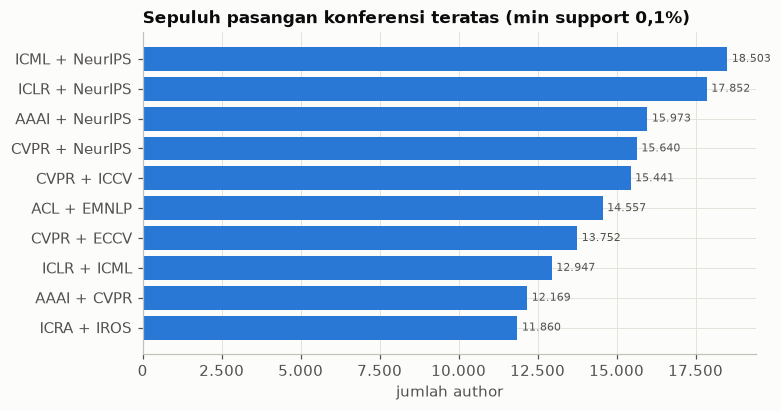

In [14]:
base = frames[min(CFG.MIN_SUPPORTS)]

def survives(itemset):
    kept = [ms for ms in CFG.MIN_SUPPORTS if frozenset(itemset) in results[ms].itemsets]
    return pct_id(max(kept) * 100)

pairs = base[base["length"] == 2].head(CFG.TOP_K).copy()
triples = base[base["length"] == 3].head(CFG.TOP_K).copy()
for t in (pairs, triples):
    t["bertahan_sampai"] = t["itemset"].map(survives)
save_table(pairs[["names", "count", "support", "bertahan_sampai"]], "t4_fpgrowth_pasangan_teratas.csv", index=False)
save_table(triples[["names", "count", "support", "bertahan_sampai"]], "t4_fpgrowth_triple_teratas.csv", index=False)
display(pairs[["names", "count", "support", "bertahan_sampai"]].style.format({"support": "{:.4%}"}))
display(triples[["names", "count", "support", "bertahan_sampai"]].style.format({"support": "{:.4%}"}))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
plot = pairs.iloc[::-1]
ax.barh(plot["names"], plot["count"], color=CFG.BLUE)
for y, v in enumerate(plot["count"]):
    ax.annotate(fmt_id(v), (v, y), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=CFG.INK_2)
id_ticks(ax, "x")
ax.set_xlabel("jumlah author")
ax.set_title("Sepuluh pasangan konferensi teratas (min support 0,1%)")
save_fig(fig, "t4_fpgrowth_pasangan_teratas.png")

> Sepuluh pasangan teratas membentuk kelompok bidang yang jelas. Machine learning diwakili ICML + NeurIPS (18.503 author), ICLR + NeurIPS (17.852), dan ICLR + ICML (12.947). Computer vision diwakili CVPR + ICCV (15.441) dan CVPR + ECCV (13.752). NLP diwakili ACL + EMNLP (14.557), dan robotika diwakili ICRA + IROS (11.860). NeurIPS muncul pada empat dari sepuluh pasangan teratas dan delapan dari sepuluh triple teratas, sehingga menjadi penghubung antara machine learning, computer vision, dan AI umum (AAAI).
>
> ICML + NeurIPS adalah satu-satunya pasangan yang masih frequent pada 1%, dan ICLR + ICML + NeurIPS (10.413 author) adalah satu-satunya triple yang masih frequent pada 0,5%. Sisanya hanya frequent sampai 0,5% (pasangan) atau 0,1% (triple selain yang pertama).

## 6.5 Keterhubungan dan Itemset Terpanjang (Task 4.5)

Konferensi yang populer belum tentu sering muncul bersama konferensi lain. Tabel pertama menghitung, untuk sepuluh konferensi dengan support tertinggi, berapa banyak pasangan frequent pada min support 0,1% yang memuatnya, berapa persen author-nya yang hanya publish di konferensi itu, dan median jumlah konferensi per author-nya. Tabel kedua menampilkan itemset terpanjang yang ditemukan.

In [15]:
pair_items = base[base["length"] == 2]["itemset"]
degree = pd.Series([i for s in pair_items for i in s]).value_counts()
top_items = base[base["length"] == 1].head(CFG.TOP_K)
connect = pd.DataFrame({
    "konferensi": top_items["names"].to_numpy(),
    "author": top_items["count"].to_numpy(),
    "pasangan_frequent": [int(degree.get(s[0], 0)) for s in top_items["itemset"]],
})
breadth = [np.fromiter((len(t) for t in transactions if s[0] in t), dtype=np.int32) for s in top_items["itemset"]]
connect["author_hanya_di_sini_pct"] = [round(float((b == 1).mean()) * 100, 1) for b in breadth]
connect["median_konferensi_per_author"] = [float(np.median(b)) for b in breadth]
save_table(connect, "t4_fpgrowth_keterhubungan_top10.csv", index=False)
print(f"Item yang muncul pada minimal satu pasangan frequent: {degree.size} dari {(base['length'] == 1).sum()} item frequent")
display(connect)

longest = base[base["length"] >= 5][["names", "length", "count", "support"]]
save_table(longest, "t4_fpgrowth_itemset_terpanjang.csv", index=False)
venue_freq = pd.Series([v for s in longest["names"] for v in s.split(" + ")]).value_counts()
print(f"Itemset berukuran 5 atau lebih: {len(longest)}, melibatkan {venue_freq.size} konferensi")
print(venue_freq.to_string())
display(longest[longest["length"] == longest["length"].max()].style.format({"support": "{:.4%}"}))
display(longest[longest["length"] == 5].head(CFG.TOP_K // 2).style.format({"support": "{:.4%}"}))

Item yang muncul pada minimal satu pasangan frequent: 105 dari 574 item frequent


,konferensi,author,pasangan_frequent,author_hanya_di_sini_pct,median_konferensi_per_author
0,NeurIPS,57800,42,11.6,6.0
1,CVPR,47664,34,10.3,6.0
2,AAAI,46437,44,8.5,8.0
3,ICASSP,42057,41,10.6,6.0
4,EMBC,39318,4,37.4,2.0
5,HCI,37884,1,40.8,2.0
6,IGARSS,35229,4,54.2,1.0
7,EMNLP,33954,25,11.1,7.0
8,ICML,31896,24,8.4,7.0
9,IROS,31249,14,16.4,4.0


Itemset berukuran 5 atau lebih: 40, melibatkan 14 konferensi
NeurIPS           35
AAAI              29
CVPR              27
ICCV              24
ICLR              21
ECCV              20
ICML              19
ACM Multimedia     7
ACL                6
EMNLP              6
IJCAI              5
NAACL-HLT          2
ICASSP             1
WACV               1


,names,length,count,support
1281,AAAI + CVPR + ECCV + ICCV + ICLR + NeurIPS,6,2005,0.1101%
1467,CVPR + ECCV + ICCV + ICLR + ICML + NeurIPS,6,1849,0.1015%
1503,AAAI + CVPR + ECCV + ICCV + ACM Multimedia + NeurIPS,6,1827,0.1003%


,names,length,count,support
559,AAAI + CVPR + ECCV + ICCV + NeurIPS,5,3222,0.1769%
584,CVPR + ECCV + ICCV + ICLR + NeurIPS,5,3112,0.1708%
759,AAAI + CVPR + ICCV + ICLR + NeurIPS,5,2674,0.1468%
779,AAAI + CVPR + ICLR + ICML + NeurIPS,5,2651,0.1455%
808,CVPR + ICCV + ICLR + ICML + NeurIPS,5,2579,0.1416%


> Hanya 105 dari 574 konferensi frequent yang muncul pada minimal satu pasangan frequent. Popularitas tidak sama dengan keterhubungan. AAAI (44 pasangan), NeurIPS (42), ICASSP (41), dan CVPR (34) terhubung luas. Sebaliknya, EMBC dan IGARSS, yang termasuk sepuluh konferensi terbesar, masing-masing hanya muncul pada empat pasangan, dan HCI hanya pada satu pasangan. Penyebabnya terlihat pada dua kolom terakhir. Author EMBC, HCI, dan IGARSS biasanya hanya publish di satu atau dua konferensi (median 2, 2, dan 1), dan 37,4%, 40,8%, serta 54,2% di antaranya tidak pernah publish di konferensi lain. Author NeurIPS dan ICASSP biasanya publish di enam konferensi, dan hanya 11,6% serta 10,6% yang publish di satu konferensi saja. Author EMBC, HCI, dan IGARSS yang publish di tempat lain tersebar ke banyak konferensi berbeda, sehingga tidak ada pasangan yang mencapai 1.822 author.
>
> Itemset terpanjang berisi enam konferensi, yaitu AAAI + CVPR + ECCV + ICCV + ICLR + NeurIPS (2.005 author) dan dua itemset lain dengan count di atas 1.800. Seluruh 40 itemset berukuran lima atau enam hanya melibatkan 14 konferensi, dan NeurIPS ada pada 35 di antaranya. Pola panjang hanya muncul di inti AI, machine learning, dan computer vision.

---

# Interpretasi (Task 4.6) <a name="7"></a>

---

**Pola publikasi.** Kombinasi konferensi yang frequent hampir seluruhnya terjadi di dalam satu bidang (machine learning, computer vision, NLP, robotika) atau di antara bidang yang bertetangga dekat, yaitu machine learning dengan computer vision dan AI umum. Artinya, di antara kombinasi yang cukup besar untuk melewati ambang, author biasanya publish di beberapa konferensi dalam bidang yang sama. Hasil ini tidak membuktikan bahwa author jarang berpindah bidang, karena kombinasi lintas bidang dapat saja banyak secara total tetapi tersebar ke banyak pasangan kecil yang tidak lolos ambang.

**Inti AI, machine learning, dan computer vision.** NeurIPS, ICML, ICLR, AAAI, CVPR, ICCV, dan ECCV adalah satu-satunya kelompok yang menghasilkan itemset berukuran lima dan enam. Banyak author di kelompok ini menerbitkan di banyak konferensi besar sekaligus, dan NeurIPS menjadi titik temu kelompok tersebut.

**Popularitas dan keterhubungan berbeda.** Konferensi besar seperti EMBC, IGARSS, dan HCI hampir tidak membentuk pasangan frequent, sedangkan ICASSP terhubung dengan 41 konferensi lain. Pertanyaan apakah konferensi terpopuler juga memiliki asosiasi terkuat dijawab dengan lift pada Task 5, karena support pasangan yang tinggi juga dapat muncul hanya karena kedua konferensinya besar.

**Pemilihan min support.** Hanya 0,1% yang menghasilkan pola kombinasi yang cukup kaya. Pada 1% dan 2% hasilnya hampir seluruhnya konferensi tunggal, sehingga Task 5 akan memakai hasil 0,1% sebagai dasar utama.

**Keterbatasan.**

1. Item adalah seri konferensi berdasarkan key DBLP. Beberapa acara dipecah DBLP menjadi konferensi utama dan workshop dengan key berbeda, misalnya `iccv` (ICCV) dan `iccvw` (ICCV Workshops), sehingga author yang hanya publish di workshop tidak terhitung pada konferensi utamanya. Key dengan singkatan sama, misalnya `icis`, `ACISicis`, dan `icis2`, adalah konferensi yang memang berbeda dan benar dipisah.
2. Identitas author mengikuti disambiguasi DBLP. Dua orang dengan nama sama dapat tergabung, dan satu orang dapat tercatat dengan dua nama.
3. Support menghitung author, bukan paper. Author yang menerbitkan satu paper dan author yang menerbitkan puluhan paper di konferensi yang sama dihitung sama.
4. Transaksi author-based menggabungkan seluruh 2015-2025, sehingga dua konferensi dapat muncul bersama walaupun dipakai pada tahun yang berbeda. Pengaruh waktu dianalisis pada Bagian E dengan author-year-based database.

---

# Ringkasan dan Langkah Berikutnya <a name="8"></a>

---

| Task | Hasil | Bagian |
|---|---|---|
| 4.1 | FP-Growth pada empat min support menghasilkan 1.514, 88, 30, dan 6 frequent itemsets, identik dengan `mlxtend` | 4, 5 |
| 4.2 | 1-, 2-, dan 3-itemset: 574, 393, 348 (0,1%); 66, 21, 1 (0,5%); 29, 1, 0 (1%); 6, 0, 0 (2%) | 6.1 |
| 4.3 | Sepuluh teratas selalu konferensi tunggal (NeurIPS, CVPR, AAAI); pasangan teratas ICML + NeurIPS dengan support 1,02% | 6.2 |
| 4.4 | Jumlah itemset turun 17,2 kali dari 0,1% ke 0,5% dan 252 kali dari 0,1% ke 2%; itemset besar hilang lebih dulu | 6.3 |
| 4.5 | Pasangan teratas ICML + NeurIPS, ICLR + NeurIPS, AAAI + NeurIPS; triple teratas ICLR + ICML + NeurIPS; hanya 105 dari 574 konferensi frequent yang membentuk pasangan frequent | 6.4, 6.5 |
| 4.6 | Pola terbentuk per bidang, NeurIPS menjadi penghubung, dan popularitas berbeda dengan keterhubungan | 7 |

Frequent itemsets setiap min support disimpan di `outputs/fpgrowth/itemsets_<tag>.parquet` (kolom `itemset`, `length`, `count`, `support`, `names`). Notebook `05_rules` membangkitkan association rules dari berkas ini, dan notebook `06_performance` membandingkan FP-Growth dengan Apriori dari notebook `03_apriori`.